# Figure 3: PCA of TMB-associated gene expression

PCA on TMB-axis genes across TCGA pan-cancer samples, split by PQC and non-PQC gene sets.

In [1]:
import socket, os, sys
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

mpl.rcParams["pdf.fonttype"] = 42

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

WORKING_DIR = f"{BASE_DIR}/data/tcga_xena"
os.chdir(WORKING_DIR)

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

In [2]:
color_df = pd.read_csv(f"{BASE_DIR}/local/figures/tcga_hex_color_codes.csv")
TCGA_COLORS = dict(zip(color_df["cancer_type"], color_df["cancer_type_color"]))

## Load data

In [3]:
expr = pd.read_csv(f"{WORKING_DIR}/data_ready/tcga_regression_ready_imputed.csv")

meta_cols = ["log_mut", "type", "cancer_type", "barcode"]
all_types = sorted(expr["cancer_type"].unique())

In [15]:
expr.shape

(9104, 19603)

In [4]:
set(all_types)-set(color_df["cancer_type"])

set()

In [5]:
tmb_weights = pd.read_csv(
    f"{BASE_DIR}/analysis/01_axis_analysis/bh/axes/tcga_tmb_genes_posBeta.tsv", sep="\t"
)
pqc_genes = pd.read_csv(f"{BASE_DIR}/data/corum/pqc_annotation.tsv", sep="\t")
pqc_genes.loc[pqc_genes["Hugo"] == "TOR4A", "Hugo"] = "C9orf167"
pqc_genes.loc[pqc_genes["Hugo"] == "FAXC", "Hugo"] = "C6orf168"

In [6]:
expr_genes = set(expr.columns)
axis_genes = set(tmb_weights["gene"])
pqc_gene_set = set(pqc_genes["Hugo"])

axis_all = list(axis_genes & expr_genes)
pqc_axis_genes = list(axis_genes & pqc_gene_set & expr_genes)
non_pqc_genes = list((axis_genes - pqc_gene_set) & expr_genes)

## Figure 3: PCA on TMB-associated genes

In [7]:
X_tmb = StandardScaler().fit_transform(expr[axis_all])
pca_tmb = PCA(n_components=2)
pcs_tmb = pca_tmb.fit_transform(X_tmb)
var_tmb = pca_tmb.explained_variance_ratio_

LOG_MUT_VMIN = float(np.percentile(expr["log_mut"], 5))
LOG_MUT_VMAX = float(np.percentile(expr["log_mut"], 95))
log_mut_norm = mpl.colors.Normalize(vmin=LOG_MUT_VMIN, vmax=LOG_MUT_VMAX)

print(f"PC1 variance explained: {var_tmb[0]:.1%}")
print(f"PC2 variance explained: {var_tmb[1]:.1%}")
print(f"log_mut color scale: {LOG_MUT_VMIN:.2f} to {LOG_MUT_VMAX:.2f} (5th-95th pct; higher values saturate)")


PC1 variance explained: 14.1%
PC2 variance explained: 11.0%
log_mut color scale: 1.08 to 2.90 (5th-95th pct; higher values saturate)


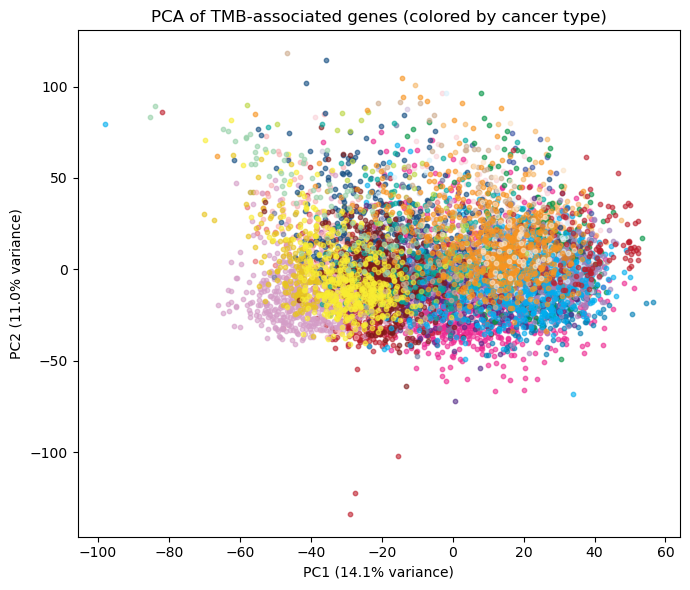

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

for ct in all_types:
    idx = expr["cancer_type"] == ct
    ax.scatter(
        pcs_tmb[idx, 0], pcs_tmb[idx, 1],
        s=10, alpha=0.6,
        color=TCGA_COLORS.get(ct, COLORS["light_gray"]),
        rasterized=True,
    )

ax.set_xlabel(f"PC1 ({var_tmb[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var_tmb[1]:.1%} variance)")
ax.set_title("PCA of TMB-associated genes (colored by cancer type)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/3c_pca_tmb_genes.pdf", dpi=1200, bbox_inches="tight")
plt.show()


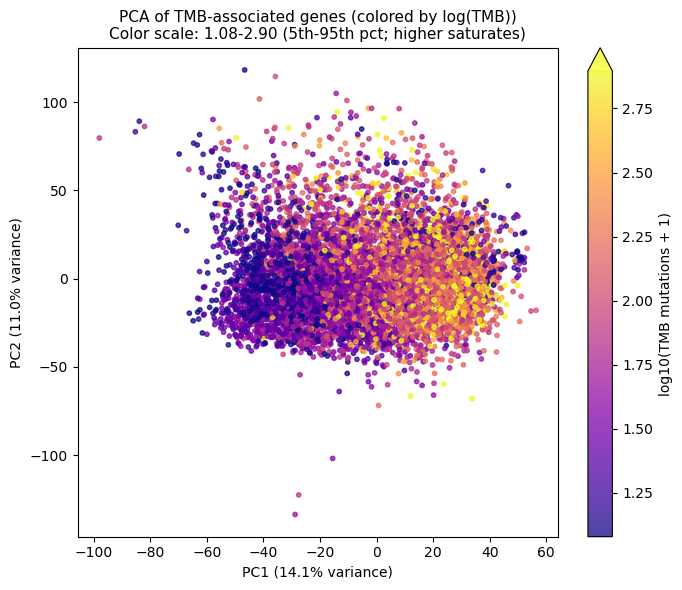

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(
    pcs_tmb[:, 0],
    pcs_tmb[:, 1],
    c=expr["log_mut"],
    cmap="plasma",
    norm=log_mut_norm,
    s=10,
    alpha=0.75,
    rasterized=True,
)

ax.set_xlabel(f"PC1 ({var_tmb[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var_tmb[1]:.1%} variance)")
ax.set_title(
    "PCA of TMB-associated genes (colored by log(TMB))\n"
    f"Color scale: {LOG_MUT_VMIN:.2f}-{LOG_MUT_VMAX:.2f} (5th-95th pct; higher saturates)",
    fontsize=11,
)
cbar = plt.colorbar(sc, ax=ax, extend="max")
cbar.set_label("log10(TMB mutations + 1)")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/pca_tmb_genes_log_mut.pdf", dpi=300, bbox_inches="tight")
plt.show()


## Supplementary: PCA on PQC-component genes

In [10]:
X_pqc = StandardScaler().fit_transform(expr[pqc_axis_genes])
pca_pqc = PCA(n_components=2)
pcs_pqc = pca_pqc.fit_transform(X_pqc)
var_pqc = pca_pqc.explained_variance_ratio_


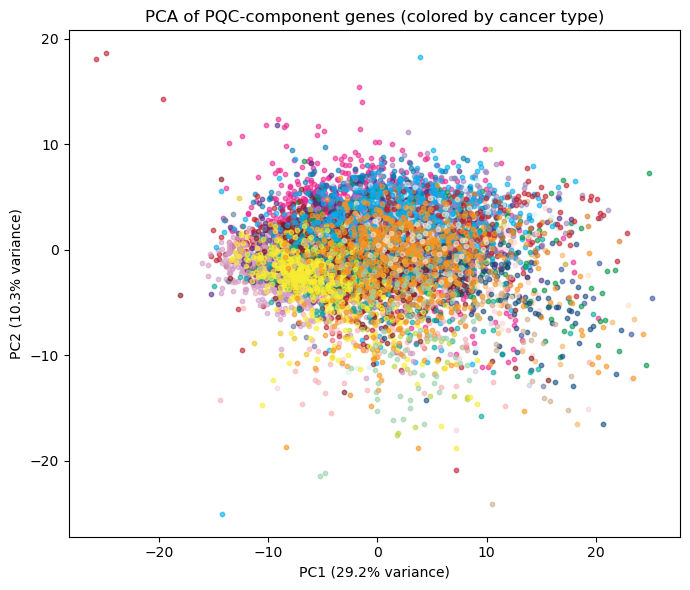

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

for ct in all_types:
    idx = expr["cancer_type"] == ct
    ax.scatter(
        pcs_pqc[idx, 0], pcs_pqc[idx, 1],
        s=10, alpha=0.6,
        color=TCGA_COLORS.get(ct, COLORS["light_gray"]),
        rasterized=True,
    )

ax.set_xlabel(f"PC1 ({var_pqc[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var_pqc[1]:.1%} variance)")
ax.set_title("PCA of PQC-component genes (colored by cancer type)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/supplementary/supp_fig3/3b_pca_pqc_genes.pdf", dpi=1200, bbox_inches="tight")
plt.show()


## Supplementary: PCA on non-PQC genes

In [12]:
X_non_pqc = StandardScaler().fit_transform(expr[non_pqc_genes])
pca_non_pqc = PCA(n_components=2)
pcs_non_pqc = pca_non_pqc.fit_transform(X_non_pqc)
var_non_pqc = pca_non_pqc.explained_variance_ratio_


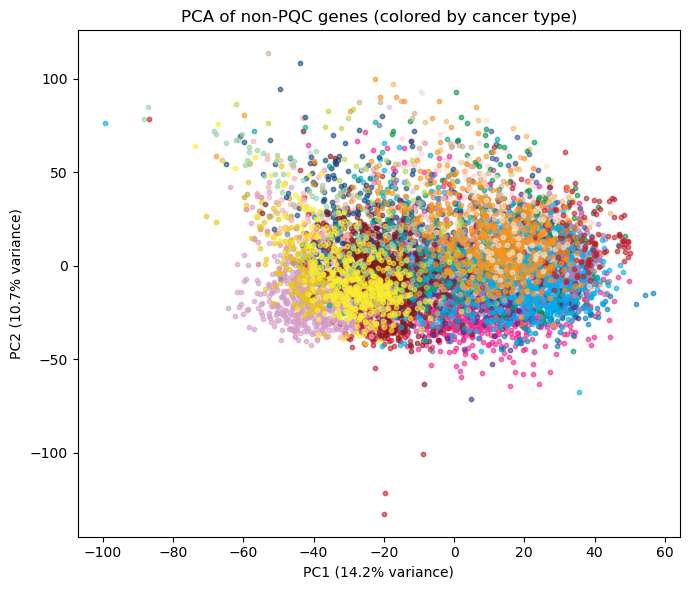

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

for ct in all_types:
    idx = expr["cancer_type"] == ct
    ax.scatter(
        pcs_non_pqc[idx, 0], pcs_non_pqc[idx, 1],
        s=10, alpha=0.6,
        color=TCGA_COLORS.get(ct, COLORS["light_gray"]),
        rasterized=True,
    )

ax.set_xlabel(f"PC1 ({var_non_pqc[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var_non_pqc[1]:.1%} variance)")
ax.set_title("PCA of non-PQC genes (colored by cancer type)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/supplementary/supp_fig3/3b_pca_non_pqc_genes.pdf", dpi=1200, bbox_inches="tight")
plt.show()


## Legend

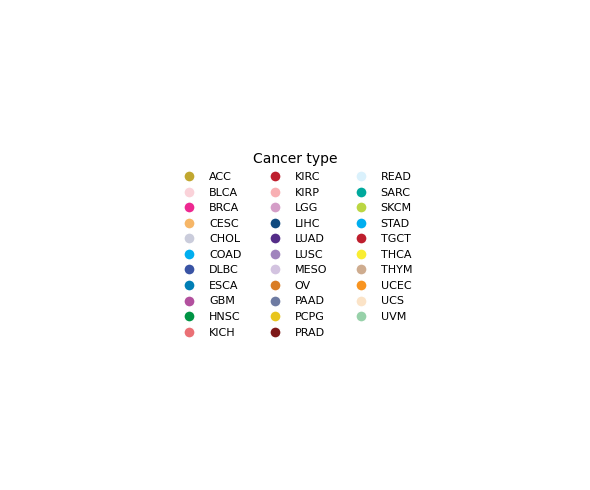

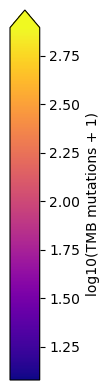

In [14]:
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=TCGA_COLORS.get(ct, COLORS["light_gray"]),
        markersize=8,
        label=ct,
    )
    for ct in all_types
]

fig, ax = plt.subplots(figsize=(6, 5))
ax.axis("off")
ax.legend(handles=handles, loc="center", frameon=False, ncol=3, fontsize=8, title="Cancer type")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/pca_legend.pdf", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(1.2, 4))
cb = mpl.colorbar.ColorbarBase(ax, cmap="plasma", norm=log_mut_norm, orientation="vertical", extend="max")
cb.set_label("log10(TMB mutations + 1)")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/pca_legend_log_mut.pdf", dpi=300, bbox_inches="tight")
plt.show()
